# NN_L5_sp500_vol

**S&P 500 daily log returns and annualised Garman-Klass range volatility, from daily open, high, low and close.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_sp500_vol/NN_L5_sp500_vol.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

$r_t=100\ln(P_t/P_{t-1})$ and $\hat\sigma^2_{GK,t}=\frac12\ln^2(H_t/L_t)-(2\ln2-1)\ln^2(C_t/O_t)$; data cut at the last complete month.

trading days = 5491   [data.n_days]
median annualised volatility (%) = 8.77   [data.gk_ann_median]


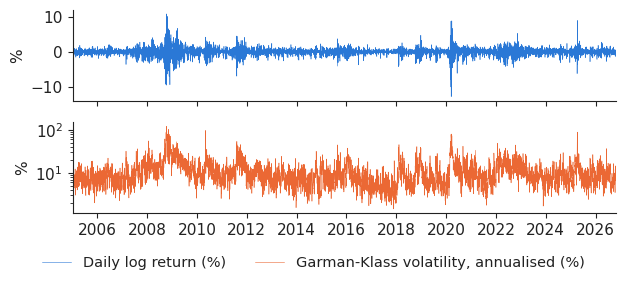

In [3]:
import matplotlib.dates as mdates
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
d = x[x.ticker == 'SP500'].set_index('date')[['open', 'high', 'low', 'close', 'adjclose']].dropna()
END = (d.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
d = d.loc[:END]; d = d[d.high > d.low]
gk = (0.5 * np.log(d.high / d.low) ** 2 - (2 * np.log(2) - 1) * np.log(d.close / d.open) ** 2).clip(lower=1e-8)
d['gk'] = gk; d['r'] = 100 * np.log(d.adjclose).diff(); d = d.dropna()
ann = np.sqrt(252 * d.gk) * 100
show('data.n_days', 'trading days', len(d)); show('data.gk_ann_median', 'median annualised volatility (%)', round(float(ann.median()), 2))
fig, axes = plt.subplots(2, 1, figsize=(6.4, 2.9), sharex=True)
axes[0].plot(d.index, d.r, color=PAL['data'], lw=0.4, label='Daily log return (%)')
axes[1].plot(d.index, ann, color=PAL['model'], lw=0.4, label='Garman-Klass volatility, annualised (%)'); axes[1].set_yscale('log')
for ax in axes: ax.set_ylabel('%'); ax.set_xlim(d.index.min(), d.index.max())
axes[1].xaxis.set_major_locator(mdates.YearLocator(2)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('sp500_vol.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()